In [1]:
'''Apply unsupervised learning techniques (K-means, DBSCAN, hierarchical clustering) to segment customer 
behavior,providing granular insights for targeted marketing strategies and customer retention programs.'''

'Apply unsupervised learning techniques (K-means, DBSCAN, hierarchical clustering) to segment customer \nbehavior,providing granular insights for targeted marketing strategies and customer retention programs.'

In [2]:
# import required libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

os.environ['LOKY_MAX_CPU_COUNT'] = '4'
warnings.filterwarnings('ignore')

In [3]:
# load and inspect the pharmacy sales dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df['revenue'] = df['units_sold'] * df['unit_price']
print('Dataset shape:', df.shape)
print('Missing values:', df.isnull().sum().sum())
df.head()

Dataset shape: (177990, 15)
Missing values: 0


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag,revenue
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0,14884.64
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1,28006.79
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1,21339.48
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0,17404.75
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0,24929.64


In [4]:
# aggregate customer behavior profiles by country age group and year
customer_df = df.groupby(['country', 'age_group', 'year']).agg(
    avg_units=('units_sold', 'mean'),
    avg_price=('unit_price', 'mean'),
    total_revenue=('revenue', 'sum'),
    avg_stock=('stock_level', 'mean'),
    covid_rate=('covid_flag', 'mean'),
    purchase_count=('units_sold', 'count')
).reset_index()

print('Customer behavior profiles:', customer_df.shape)
customer_df.head()

Customer behavior profiles: (570, 9)


,country,age_group,year,avg_units,avg_price,total_revenue,avg_stock,covid_rate,purchase_count
0,Argentina,0-12,2020,598.648352,52.569698,11679448.53,4405.206044,1.0,364
1,Argentina,0-12,2021,610.554054,56.291324,12529715.44,4394.416216,1.0,370
2,Argentina,0-12,2022,379.584848,51.789636,6407736.56,4630.118182,0.0,330
3,Argentina,0-12,2023,379.297872,52.426941,7782082.30,4616.978723,0.0,376
4,Argentina,0-12,2024,369.467456,52.622692,6532632.76,4641.926036,0.0,338


In [5]:
# standardize behavioral features and reduce dimensions with pca
features = ['avg_units', 'avg_price', 'total_revenue', 'avg_stock', 'covid_rate']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer_df[features])

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
customer_df['pca_1'] = X_pca[:, 0]
customer_df['pca_2'] = X_pca[:, 1]

print('Explained variance ratio:', np.round(pca.explained_variance_ratio_, 3))

Explained variance ratio: [0.723 0.202]


K=2 -> Silhouette Score: 0.6423
K=3 -> Silhouette Score: 0.4518
K=4 -> Silhouette Score: 0.3758
K=5 -> Silhouette Score: 0.3868
K=6 -> Silhouette Score: 0.3439
K=7 -> Silhouette Score: 0.3734
K=8 -> Silhouette Score: 0.3741


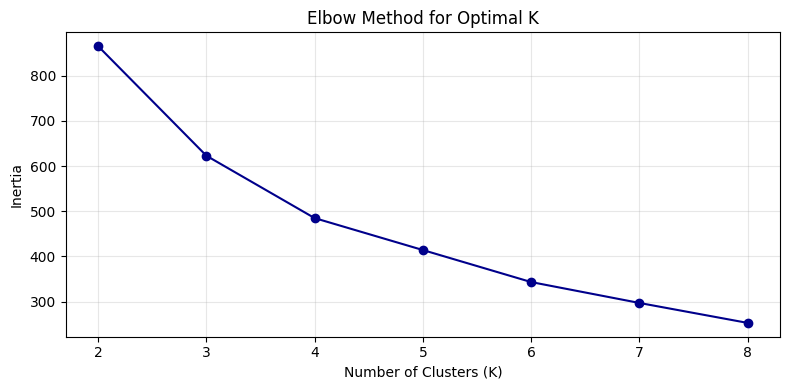

In [6]:
# evaluate elbow method and silhouette scores for k-means
k_values = range(2, 9)
inertias = []
sil_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

for k, s in zip(k_values, sil_scores):
    print(f'K={k} -> Silhouette Score: {s:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertias, marker='o', color='darkblue')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

K-Means Silhouette Score: 0.4518
kmeans_cluster
0    190
1    195
2    185
Name: count, dtype: int64


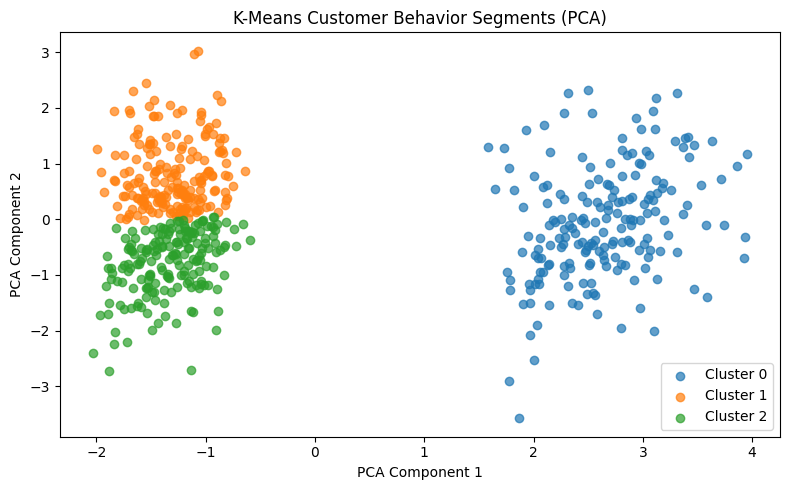

In [7]:
# apply k-means clustering and plot customer segments
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
customer_df['kmeans_cluster'] = kmeans.fit_predict(X_scaled)
kmeans_sil = silhouette_score(X_scaled, customer_df['kmeans_cluster'])

print('K-Means Silhouette Score:', round(kmeans_sil, 4))
print(customer_df['kmeans_cluster'].value_counts().sort_index())

plt.figure(figsize=(8, 5))
for c in sorted(customer_df['kmeans_cluster'].unique()):
    sub = customer_df[customer_df['kmeans_cluster'] == c]
    plt.scatter(sub['pca_1'], sub['pca_2'], label=f'Cluster {c}', alpha=0.7)

plt.title('K-Means Customer Behavior Segments (PCA)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.tight_layout()
plt.show()

DBSCAN Clusters: 3 | Noise Points: 23 | Silhouette (non-noise): 0.5760


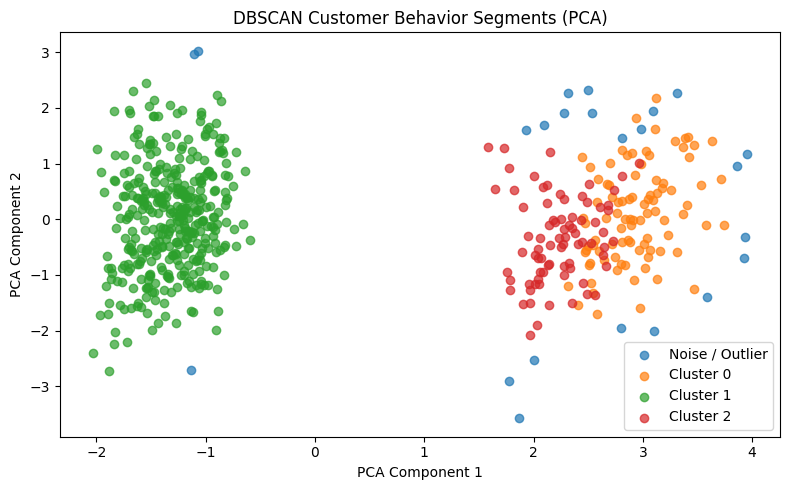

In [8]:
# apply dbscan clustering and visualize density clusters
dbscan = DBSCAN(eps=0.6, min_samples=8)
customer_df['dbscan_cluster'] = dbscan.fit_predict(X_scaled)

n_db_clusters = len(set(customer_df['dbscan_cluster'])) - (1 if -1 in customer_df['dbscan_cluster'].values else 0)
n_noise = (customer_df['dbscan_cluster'] == -1).sum()
non_noise_mask = customer_df['dbscan_cluster'] != -1
dbscan_sil = silhouette_score(X_scaled[non_noise_mask], customer_df.loc[non_noise_mask, 'dbscan_cluster'])

print(f'DBSCAN Clusters: {n_db_clusters} | Noise Points: {n_noise} | Silhouette (non-noise): {dbscan_sil:.4f}')

plt.figure(figsize=(8, 5))
for c in sorted(customer_df['dbscan_cluster'].unique()):
    sub = customer_df[customer_df['dbscan_cluster'] == c]
    lbl = 'Noise / Outlier' if c == -1 else f'Cluster {c}'
    plt.scatter(sub['pca_1'], sub['pca_2'], label=lbl, alpha=0.7)

plt.title('DBSCAN Customer Behavior Segments (PCA)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.tight_layout()
plt.show()

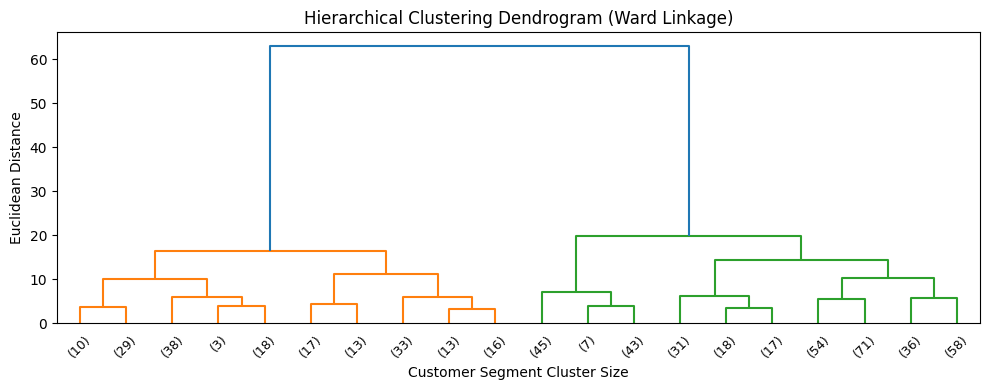

In [9]:
# plot hierarchical clustering dendrogram
linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 4))
dendrogram(linked, truncate_mode='lastp', p=20, leaf_rotation=45, leaf_font_size=9)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Customer Segment Cluster Size')
plt.ylabel('Euclidean Distance')
plt.tight_layout()
plt.show()

Hierarchical Clustering Silhouette Score: 0.4309
hier_cluster
0    190
1    285
2     95
Name: count, dtype: int64


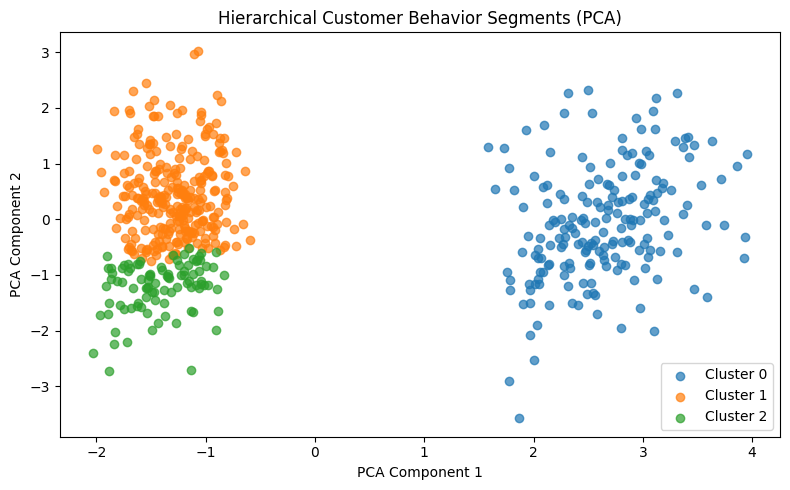

In [10]:
# apply agglomerative hierarchical clustering and visualize segments
hier = AgglomerativeClustering(n_clusters=3, linkage='ward')
customer_df['hier_cluster'] = hier.fit_predict(X_scaled)
hier_sil = silhouette_score(X_scaled, customer_df['hier_cluster'])

print('Hierarchical Clustering Silhouette Score:', round(hier_sil, 4))
print(customer_df['hier_cluster'].value_counts().sort_index())

plt.figure(figsize=(8, 5))
for c in sorted(customer_df['hier_cluster'].unique()):
    sub = customer_df[customer_df['hier_cluster'] == c]
    plt.scatter(sub['pca_1'], sub['pca_2'], label=f'Cluster {c}', alpha=0.7)

plt.title('Hierarchical Customer Behavior Segments (PCA)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.tight_layout()
plt.show()

      Algorithm  Clusters  Noise_Points  Silhouette_Score
0       K-Means         3             0            0.4518
1        DBSCAN         3            23            0.5760
2  Hierarchical         3             0            0.4309


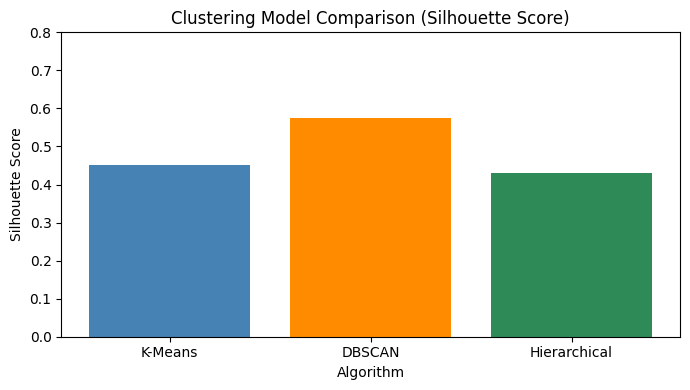

In [11]:
# compare clustering models using silhouette score
comparison_df = pd.DataFrame({
    'Algorithm': ['K-Means', 'DBSCAN', 'Hierarchical'],
    'Clusters': [3, n_db_clusters, 3],
    'Noise_Points': [0, int(n_noise), 0],
    'Silhouette_Score': [round(kmeans_sil, 4), round(dbscan_sil, 4), round(hier_sil, 4)]
})
print(comparison_df)

plt.figure(figsize=(7, 4))
plt.bar(comparison_df['Algorithm'], comparison_df['Silhouette_Score'], color=['steelblue', 'darkorange', 'seagreen'])
plt.title('Clustering Model Comparison (Silhouette Score)')
plt.xlabel('Algorithm')
plt.ylabel('Silhouette Score')
plt.ylim(0, 0.8)
plt.tight_layout()
plt.show()

In [12]:
# profile customer segments for targeted marketing and retention strategies
profile_df = customer_df.groupby('kmeans_cluster').agg(
    segment_size=('country', 'count'),
    avg_units=('avg_units', 'mean'),
    avg_price=('avg_price', 'mean'),
    avg_revenue=('total_revenue', 'mean'),
    avg_stock=('avg_stock', 'mean'),
    covid_rate=('covid_rate', 'mean')
).round(2).reset_index()

ranked_clusters = profile_df.sort_values('avg_revenue', ascending=False)['kmeans_cluster'].tolist()
strategy_map = {
    ranked_clusters[0]: (
        'High-Demand Peak Buyers',
        'Priority restocking alerts and seasonal wellness bundles',
        'VIP loyalty membership with fast refill subscriptions'
    ),
    ranked_clusters[1]: (
        'Premium Steady Buyers',
        'Cross-sell preventive vitamins and chronic care packs',
        'Tiered cashback rewards and automated refill reminders'
    ),
    ranked_clusters[2]: (
        'Value-Sensitive Regular Buyers',
        'Targeted discount coupons and multi-pack price offers',
        'Points-based retention program and free delivery thresholds'
    )
}

profile_df['segment_name'] = profile_df['kmeans_cluster'].map(lambda x: strategy_map[x][0])
profile_df['marketing_strategy'] = profile_df['kmeans_cluster'].map(lambda x: strategy_map[x][1])
profile_df['retention_program'] = profile_df['kmeans_cluster'].map(lambda x: strategy_map[x][2])

profile_df[['kmeans_cluster', 'segment_name', 'segment_size', 'avg_units', 'avg_price', 'avg_revenue', 'marketing_strategy', 'retention_program']]

,kmeans_cluster,segment_name,segment_size,avg_units,avg_price,avg_revenue,marketing_strategy,retention_program
0,0,High-Demand Peak Buyers,190,597.71,52.61,9843040.24,Priority restocking alerts and seasonal wellne...,VIP loyalty membership with fast refill subscr...
1,1,Premium Steady Buyers,195,371.00,53.80,6159185.97,Cross-sell preventive vitamins and chronic car...,Tiered cashback rewards and automated refill r...
2,2,Value-Sensitive Regular Buyers,185,375.18,51.19,6051855.74,Targeted discount coupons and multi-pack price...,Points-based retention program and free delive...


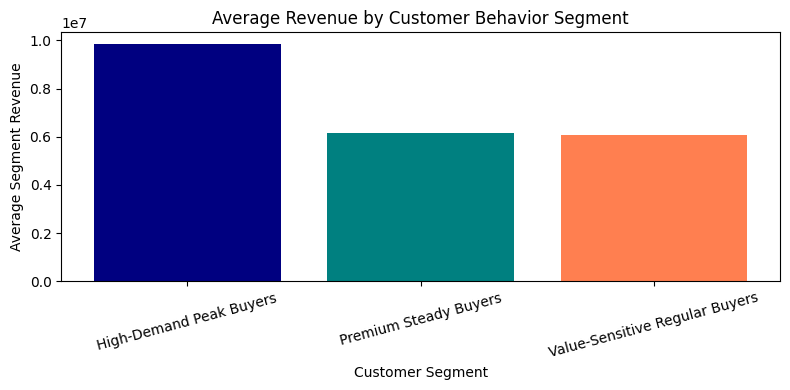

In [13]:
# visualize average revenue across customer behavior segments
plt.figure(figsize=(8, 4))
plt.bar(profile_df['segment_name'], profile_df['avg_revenue'], color=['navy', 'teal', 'coral'])
plt.title('Average Revenue by Customer Behavior Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Segment Revenue')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()